# Skoki w jednej sekundzie

In [1]:
from cProfile import label

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

## Wczytanie danych

In [3]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)

In [4]:
data = data_raw.to_pandas()
ilosc_danych = len(data)
ilosc_danych

11110277

In [5]:
czasy = data['found_at']
czasy = czasy.sort_values().reset_index(drop=True)
czasy

0          2025-08-03 06:27:44
1          2025-08-03 06:27:44
2          2025-08-03 06:27:44
3          2025-08-03 06:27:44
4          2025-08-03 06:27:45
                   ...        
11110272   2025-10-09 20:44:16
11110273   2025-10-09 20:44:17
11110274   2025-10-09 20:44:19
11110275   2025-10-09 20:44:19
11110276   2025-10-09 20:44:20
Name: found_at, Length: 11110277, dtype: datetime64[ns]

### Ile było skokow w kazdej sekundzie

In [6]:
ile_obserwacji_w_sekundzie = czasy.value_counts()
ile_obserwacji_w_sekundzie

found_at
2025-08-11 05:49:09    321
2025-08-11 05:41:58    300
2025-08-14 21:41:17    290
2025-08-07 00:19:06    288
2025-08-11 05:40:55    285
                      ... 
2025-10-09 20:43:58      1
2025-10-09 20:44:14      1
2025-10-09 20:44:16      1
2025-10-09 20:44:17      1
2025-10-09 20:44:20      1
Name: count, Length: 2211272, dtype: int64

In [32]:
type(ile_obserwacji_w_sekundzie)

pandas.Series

## Uwaga! Nie ma zer, trzeba je policzyć

In [19]:
czasy_skokow = ile_obserwacji_w_sekundzie.index
czasy_skokow

DatetimeIndex(['2025-08-11 05:49:09', '2025-08-11 05:41:58',
               '2025-08-14 21:41:17', '2025-08-07 00:19:06',
               '2025-08-11 05:40:55', '2025-08-06 15:31:17',
               '2025-08-06 18:20:49', '2025-08-17 14:43:11',
               '2025-08-08 13:23:19', '2025-08-11 05:42:36',
               ...
               '2025-10-09 20:43:28', '2025-10-09 20:43:48',
               '2025-10-09 20:43:50', '2025-10-09 20:43:54',
               '2025-10-09 20:43:57', '2025-10-09 20:43:58',
               '2025-10-09 20:44:14', '2025-10-09 20:44:16',
               '2025-10-09 20:44:17', '2025-10-09 20:44:20'],
              dtype='datetime64[ns]', name='found_at', length=2211272, freq=None)

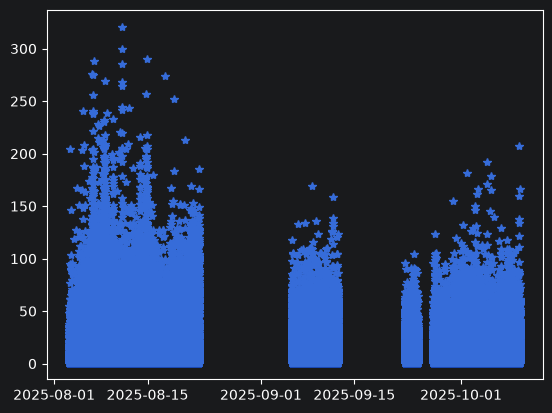

In [18]:
plt.plot(ile_obserwacji_w_sekundzie, "*")
plt.show()

## Mamy 4 okresy, trzeba podzielic dane

In [20]:
okres1 = czasy_skokow[czasy_skokow < np.datetime64('2025-09-01 20:44:17')]
okres1

DatetimeIndex(['2025-08-11 05:49:09', '2025-08-11 05:41:58',
               '2025-08-14 21:41:17', '2025-08-07 00:19:06',
               '2025-08-11 05:40:55', '2025-08-06 15:31:17',
               '2025-08-06 18:20:49', '2025-08-17 14:43:11',
               '2025-08-08 13:23:19', '2025-08-11 05:42:36',
               ...
               '2025-08-22 17:46:05', '2025-08-22 17:46:14',
               '2025-08-22 17:46:39', '2025-08-22 17:47:19',
               '2025-08-22 17:48:04', '2025-08-22 17:48:07',
               '2025-08-22 17:48:13', '2025-08-22 17:48:29',
               '2025-08-22 17:48:42', '2025-08-22 17:49:10'],
              dtype='datetime64[ns]', name='found_at', length=1236735, freq=None)

In [22]:
reszta1 = czasy_skokow[czasy_skokow > np.datetime64('2025-09-01 20:44:17')]
okres2 = reszta1[reszta1 < np.datetime64('2025-09-15 20:44:17')]
okres2

DatetimeIndex(['2025-09-08 13:58:07', '2025-09-11 20:24:09',
               '2025-09-11 18:12:09', '2025-09-09 06:04:08',
               '2025-09-07 14:12:05', '2025-09-11 20:56:09',
               '2025-09-06 12:58:04', '2025-09-11 18:10:13',
               '2025-09-11 14:59:19', '2025-09-11 15:48:11',
               ...
               '2025-09-12 14:05:44', '2025-09-12 14:06:14',
               '2025-09-12 14:07:42', '2025-09-12 14:07:48',
               '2025-09-12 14:09:55', '2025-09-12 14:10:22',
               '2025-09-12 14:11:24', '2025-09-12 14:12:10',
               '2025-09-12 14:13:07', '2025-09-12 14:14:18'],
              dtype='datetime64[ns]', name='found_at', length=117969, freq=None)

In [23]:
reszta2 = reszta1[reszta1 > np.datetime64('2025-09-15 20:44:17')]

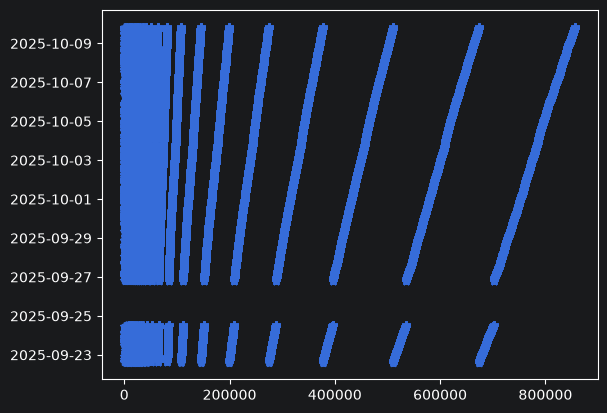

In [25]:
plt.plot(reszta2, "*")
plt.show()

In [26]:
okres3 = reszta2[reszta2 < np.datetime64('2025-09-26 02:44:17')]
okres3

DatetimeIndex(['2025-09-23 22:00:42', '2025-09-22 15:34:19',
               '2025-09-23 12:21:16', '2025-09-23 23:26:03',
               '2025-09-22 18:55:18', '2025-09-24 03:35:35',
               '2025-09-24 04:40:44', '2025-09-23 20:20:36',
               '2025-09-24 11:11:57', '2025-09-23 23:16:51',
               ...
               '2025-09-24 12:56:12', '2025-09-24 12:56:18',
               '2025-09-24 12:56:20', '2025-09-24 12:56:22',
               '2025-09-24 12:56:23', '2025-09-24 12:56:35',
               '2025-09-24 12:56:37', '2025-09-24 12:56:39',
               '2025-09-24 12:56:40', '2025-09-24 12:56:41'],
              dtype='datetime64[ns]', name='found_at', length=114105, freq=None)

In [27]:
okres4 = reszta2[reszta2 > np.datetime64('2025-09-26 02:44:17')]
okres4

DatetimeIndex(['2025-10-09 17:59:51', '2025-10-04 21:06:51',
               '2025-10-01 23:02:24', '2025-10-05 10:50:48',
               '2025-10-04 21:06:53', '2025-10-03 13:37:56',
               '2025-10-09 18:43:46', '2025-10-05 10:54:31',
               '2025-10-03 09:50:05', '2025-10-09 18:00:05',
               ...
               '2025-10-09 20:43:28', '2025-10-09 20:43:48',
               '2025-10-09 20:43:50', '2025-10-09 20:43:54',
               '2025-10-09 20:43:57', '2025-10-09 20:43:58',
               '2025-10-09 20:44:14', '2025-10-09 20:44:16',
               '2025-10-09 20:44:17', '2025-10-09 20:44:20'],
              dtype='datetime64[ns]', name='found_at', length=742463, freq=None)

In [28]:
np.min(okres4)

Timestamp('2025-09-26 19:27:45')

## Obliczam, kiedy nie było skokow

In [34]:
brakujace_indeksy = pd.DatetimeIndex([])

for okres in [okres1, okres2, okres3, okres4]:
    start = np.min(okres)
    stop = np.max(okres)
    full_range = pd.date_range(start, stop, freq="1s")

    missing = full_range.difference(okres)
    missing
    brakujace_indeksy = brakujace_indeksy.union(missing)

## Dołaczam momenty bez skoku do danych

In [35]:
 skoki = pd.concat([ile_obserwacji_w_sekundzie, pd.Series(0, index=missing)])
 skoki

2025-08-11 05:49:09    321
2025-08-11 05:41:58    300
2025-08-14 21:41:17    290
2025-08-07 00:19:06    288
2025-08-11 05:40:55    285
                      ... 
2025-10-09 20:44:01      0
2025-10-09 20:44:04      0
2025-10-09 20:44:06      0
2025-10-09 20:44:10      0
2025-10-09 20:44:18      0
Length: 2596605, dtype: int64

In [38]:
np.mean(skoki)

np.float64(4.27877054846617)

In [39]:
np.var(skoki)

np.float64(53.37888319058884)

In [40]:
np.quantile(skoki, 0.99)

np.float64(35.0)

## Rozkład Poissona

In [45]:
import math

def pois(k, lamb):
    return lamb**k * np.exp(-lamb) / math.factorial(k)

In [47]:
x = [i for i in range(0, 40)]
y = [pois(i, np.mean(skoki)) for i in range(0, 40)]

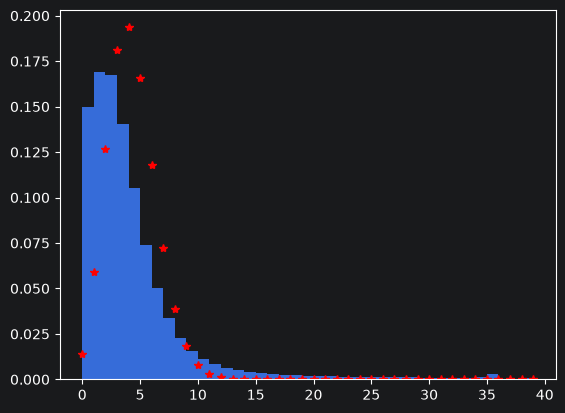

In [48]:
plt.hist(skoki, bins = [i for i in range(0,40)], density=True)
plt.plot(x, y, 'r*')
plt.show()

## Rozkład dwumianowy

In [51]:
x = skoki

mean = x.mean()
var = x.var(ddof=1)

if mean <= 0:
    print("Nie można oszacować parametrów: średnia musi być dodatnia.")
elif var <= 0 or var >= mean:
    print("Brak poprawnych estymatorów metodą momentów.")
    print("Dla modelu dwumianowego wariancja powinna być mniejsza od średniej.")
else:
    p_hat = 1 - var / mean
    n_hat = mean / p_hat

    print("Średnia:", mean)
    print("Wariancja:", var)
    print("Estymowane p:", p_hat)
    print("Estymowane n:", n_hat)
    print("n zaokrąglone:", round(n_hat))

Brak poprawnych estymatorów metodą momentów.
Dla modelu dwumianowego wariancja powinna być mniejsza od średniej.


## Usuwam 0,1% najwyższych wartości

In [22]:
kwantyl999 = np.quantile(czasy_oczekiwania, 0.999)
czasy_oczekiwania_q_999 = [i for i in czasy_oczekiwania if i < kwantyl999]

In [23]:
np.mean(czasy_oczekiwania_q_999)

np.float64(0.2972861390243581)

In [24]:
np.var(czasy_oczekiwania_q_999)

np.float64(0.7529873774284748)

# Testy na rozkład wykładniczy

# Analiza poprzez ilosc pojawienia sie zjawiska w danej sekundzie

In [34]:
len(ile_obserwacji_w_sekundzie)

2211272

In [35]:
mask = ile_obserwacji_w_sekundzie == 1
mask

found_at
2025-08-11 05:49:09    False
2025-08-11 05:41:58    False
2025-08-14 21:41:17    False
2025-08-07 00:19:06    False
2025-08-11 05:40:55    False
                       ...  
2025-10-09 20:43:58     True
2025-10-09 20:44:14     True
2025-10-09 20:44:16     True
2025-10-09 20:44:17     True
2025-10-09 20:44:20     True
Name: count, Length: 2211272, dtype: bool

In [36]:
sum(mask)

435621

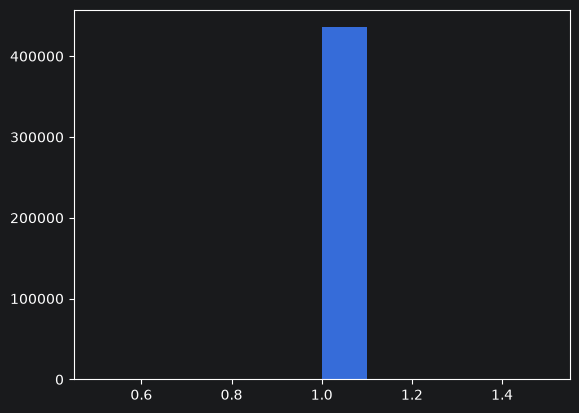

In [37]:
plt.hist(ile_obserwacji_w_sekundzie[mask])
plt.show()

In [38]:
mask = ile_obserwacji_w_sekundzie == 2
sum(mask)

432064

In [75]:
total = 0
l = []
for i in range(1, 40):
    mask = ile_obserwacji_w_sekundzie == i
    s = sum(mask)
    print(f"Jest {s} chwil w których przybyło {i} tranzakcji")
    total += s
    l.append(s)

print(f"Jest {total} chwil w których przybyło poniżej 40 tranzakcji")

Jest 0 chwil w których przybyło 0 tranzakcji
Jest 435621 chwil w których przybyło 1 tranzakcji
Jest 432064 chwil w których przybyło 2 tranzakcji
Jest 361747 chwil w których przybyło 3 tranzakcji
Jest 271639 chwil w których przybyło 4 tranzakcji
Jest 190723 chwil w których przybyło 5 tranzakcji
Jest 130119 chwil w których przybyło 6 tranzakcji
Jest 87533 chwil w których przybyło 7 tranzakcji
Jest 59245 chwil w których przybyło 8 tranzakcji
Jest 40811 chwil w których przybyło 9 tranzakcji
Jest 29078 chwil w których przybyło 10 tranzakcji
Jest 21307 chwil w których przybyło 11 tranzakcji
Jest 16202 chwil w których przybyło 12 tranzakcji
Jest 12969 chwil w których przybyło 13 tranzakcji
Jest 10326 chwil w których przybyło 14 tranzakcji
Jest 8528 chwil w których przybyło 15 tranzakcji
Jest 7552 chwil w których przybyło 16 tranzakcji
Jest 6403 chwil w których przybyło 17 tranzakcji
Jest 5733 chwil w których przybyło 18 tranzakcji
Jest 5168 chwil w których przybyło 19 tranzakcji
Jest 4675 chw

In [40]:
np.mean(ile_obserwacji_w_sekundzie)

np.float64(5.0243827986787695)

In [41]:
np.var(ile_obserwacji_w_sekundzie)

np.float64(58.93436734722984)

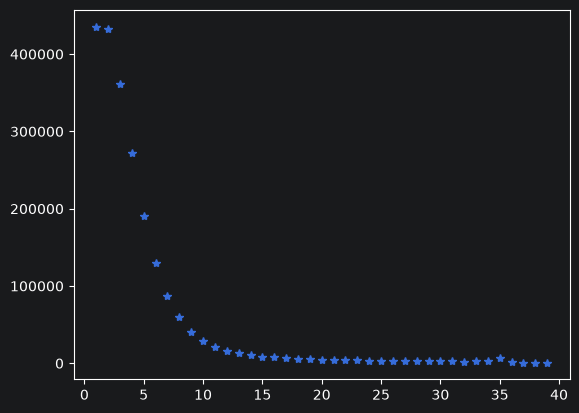

In [42]:
plt.plot([i for i in range(0,40)], l, "*")
plt.show()

Analiza ze względu na możliwość dawania wielu tranzakcji na raz; możliwe, że kilku ludzi daje naraz "paczki", co zaburza proces - sprawdzic po adresach; analiza danych adresowych, opisać proces Xt,

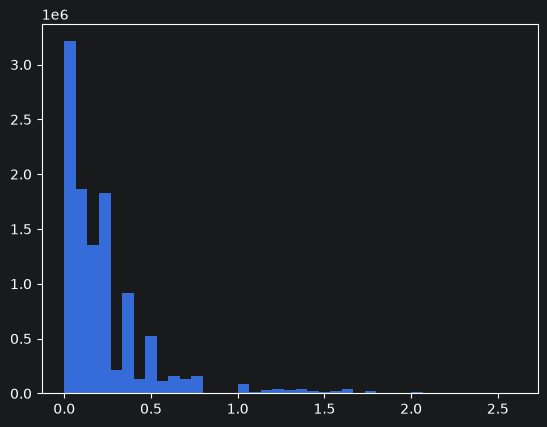

In [43]:
plt.hist(czasy_oczekiwania_q_99, bins = [i/15 for i in range(0, 40)])
plt.show()


To bez sensu, jest luka pomiędzy 0.8 a 1 ze względu na metodologie

# Analiza czasów przybycia

In [44]:
data

,tx_id,conf_block_hash,found_at,mined_at,fee_rate_original,waittime,weight_original,size_original,min_respend_blocks,child_txid,...,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,log_n_in,log_n_out,is_consolidation,is_coinjoin,is_datacarrying
0,e0062963708a3f49c89b6cb252a57808188a05752cf7db...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:27,1.0,2490,452,113,11,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
1,766ade3892c0c796756c135f80adaea15545a89d1e8dfd...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,548,137,3499,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
2,4e491c09d81817d21afb647820c374143a30d7334b635e...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,576,144,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.386294,0,0,0
3,2a1f8638e69d39bb57c78f6e40558c61eccf857e1ddaea...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:26,1.0,2472,328,82,35,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,0.693147,0,0,0
4,ce72aa8d04042d3aa0ebc9588529adfcecedd0fbda5fd2...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:25,1.0,2471,11808,2952,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,4.276666,0.693147,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11110272,402fc499134d0f9a61df1d3f64dc973b7266997d454c42...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,732,183,35,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.386294,0,0,1
11110273,05e746c504ef75534a0b729e72cc501a85ff90da45c7df...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:39,3.0,30,616,154,655,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.098612,1.098612,0,0,0
11110274,b3238a3931e970786a3d74701193f2adffa1b4e67f8a53...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,820,205,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.609438,0.693147,1,0,0
11110275,131c10ccd05131c463240ad48c1af79486d5a362d3bd84...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:41,1.0,32,884,221,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.609438,0,0,1


In [45]:
czasy_wykopania = data['mined_at'] - data["found_at"]
czasy_wykopania

0          0 days 00:41:30
1          0 days 00:41:29
2          0 days 00:41:29
3          0 days 00:41:12
4          0 days 00:41:11
                 ...      
11110272   0 days 00:00:29
11110273   0 days 00:00:30
11110274   0 days 00:00:29
11110275   0 days 00:00:32
11110276   0 days 00:00:32
Length: 11110277, dtype: timedelta64[ns]

In [46]:
czasy_wykopania = czasy_wykopania.apply(lambda x: x.total_seconds())
czasy_wykopania

0           2490.0
1           2489.0
2           2489.0
3           2472.0
4           2471.0
             ...  
11110272      29.0
11110273      30.0
11110274      29.0
11110275      32.0
11110276      32.0
Length: 11110277, dtype: float64

In [47]:
np.min(czasy_wykopania)

np.float64(0.0)

In [48]:
np.max(czasy_wykopania)

np.float64(1172305.0)

In [49]:
np.mean(czasy_wykopania)

np.float64(1432.085830983332)

In [50]:
np.var(czasy_wykopania)

np.float64(103720731.16828401)

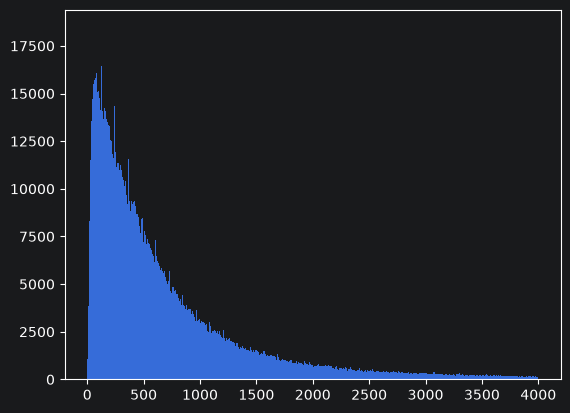

In [51]:
plt.hist(czasy_wykopania, bins = [i for i in range(0, 4000)])
plt.show()

In [52]:
q99 = np.quantile(czasy_wykopania, 0.99)
q99

np.float64(16398.0)

In [53]:
q995 = np.quantile(czasy_wykopania, 0.995)
q995

np.float64(31704.0)

In [54]:
czasy_wykopania99 = czasy_wykopania[czasy_wykopania < q99]
czasy_wykopania99

0           2490.0
1           2489.0
2           2489.0
3           2472.0
4           2471.0
             ...  
11110272      29.0
11110273      30.0
11110274      29.0
11110275      32.0
11110276      32.0
Length: 10999170, dtype: float64

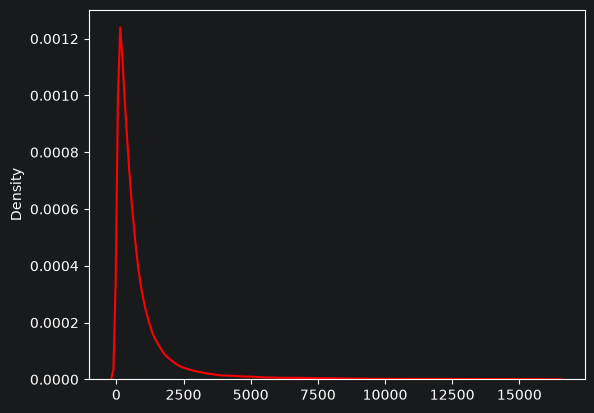

In [55]:
sns.kdeplot(czasy_wykopania99, bw_adjust=1, label="1", color="red")


plt.show()

# Ile danych przychodzi w jednej sekundzie

In [56]:
ile_obserwacji_w_sekundzie

found_at
2025-08-11 05:49:09    321
2025-08-11 05:41:58    300
2025-08-14 21:41:17    290
2025-08-07 00:19:06    288
2025-08-11 05:40:55    285
                      ... 
2025-10-09 20:43:58      1
2025-10-09 20:44:14      1
2025-10-09 20:44:16      1
2025-10-09 20:44:17      1
2025-10-09 20:44:20      1
Name: count, Length: 2211272, dtype: int64

In [57]:
np.mean(ile_obserwacji_w_sekundzie)

np.float64(5.0243827986787695)

In [58]:
np.var(ile_obserwacji_w_sekundzie)

np.float64(58.93436734722984)

In [59]:
q99 = np.quantile(ile_obserwacji_w_sekundzie, 0.99)
q99

np.float64(37.0)

In [60]:
q995 = np.quantile(ile_obserwacji_w_sekundzie, 0.995)
q995

np.float64(52.0)

In [61]:
q999 = np.quantile(ile_obserwacji_w_sekundzie, 0.999)
q999

np.float64(87.0)

## Analiza ogona

In [62]:
ogon = ile_obserwacji_w_sekundzie[ile_obserwacji_w_sekundzie > q99]
ogon

found_at
2025-08-11 05:49:09    321
2025-08-11 05:41:58    300
2025-08-14 21:41:17    290
2025-08-07 00:19:06    288
2025-08-11 05:40:55    285
                      ... 
2025-10-09 15:50:29     38
2025-10-09 15:51:45     38
2025-10-09 16:57:46     38
2025-10-09 16:59:47     38
2025-10-09 19:22:38     38
Name: count, Length: 21187, dtype: int64

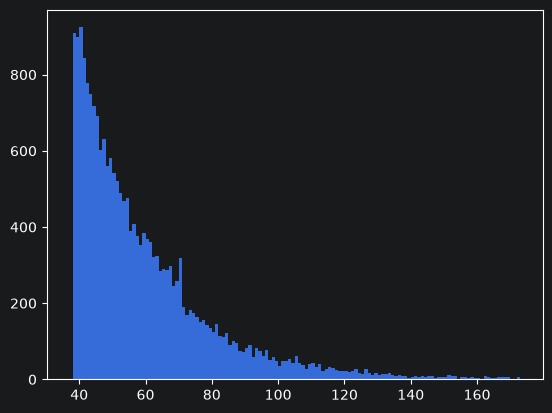

In [63]:
plt.hist(ogon, bins = [i for i in range(int(q99), 2* int(q999))])
plt.show()

Zostawie wszystko ponizej 140

In [64]:
ile140 = ile_obserwacji_w_sekundzie[ile_obserwacji_w_sekundzie < 140]
ile140

found_at
2025-08-22 16:01:09    139
2025-08-22 16:23:09    139
2025-09-11 18:12:09    139
2025-08-05 08:42:44    138
2025-08-06 18:32:49    138
                      ... 
2025-10-09 20:43:58      1
2025-10-09 20:44:14      1
2025-10-09 20:44:16      1
2025-10-09 20:44:17      1
2025-10-09 20:44:20      1
Name: count, Length: 2210965, dtype: int64

In [65]:
np.mean(ile140)

np.float64(5.0007422098495455)

In [66]:
np.var(ile140)

np.float64(54.76063157129744)

## Wykres czestosci pojawien sie tranzakcji

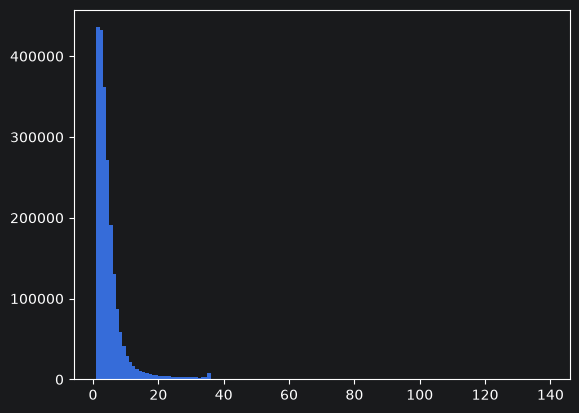

In [67]:
plt.hist(ile140, bins = [i for i in range(1, 140)])
plt.show()

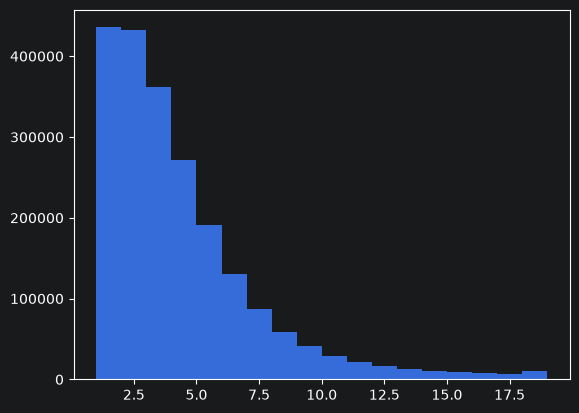

In [68]:
plt.hist(ile140, bins = [i for i in range(1, 20)])
plt.show()

In [69]:
ile15 = ile_obserwacji_w_sekundzie[ile_obserwacji_w_sekundzie < 15]
ile15

found_at
2025-08-03 07:03:26    14
2025-08-03 07:16:36    14
2025-08-03 07:26:42    14
2025-08-03 07:30:17    14
2025-08-03 07:43:51    14
                       ..
2025-10-09 20:43:58     1
2025-10-09 20:44:14     1
2025-10-09 20:44:16     1
2025-10-09 20:44:17     1
2025-10-09 20:44:20     1
Name: count, Length: 2099384, dtype: int64

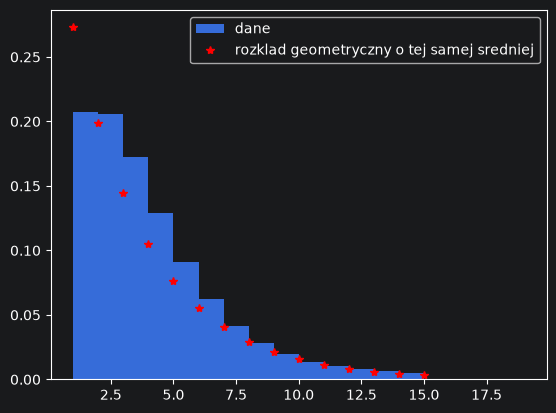

In [70]:
plt.hist(ile15,  bins = [i for i in range(1, 20)], density = True, label = "dane")

p = 1 / np.mean(ile15)
x = np.linspace(1, 15, 15)
f = (1-p)**(x-1) * p
plt.plot(x, f, 'r*', label='rozklad geometryczny o tej samej sredniej')

plt.legend()
plt.show()

### Zmienność liczby zdarzeń (Fano factor)

In [71]:
F = np.var(ile140) / np.mean(ile140)
F

np.float64(10.950500800349193)

# Analiza pakietow pojawiajacych sie w tej samej sekundzie

In [72]:
data

,tx_id,conf_block_hash,found_at,mined_at,fee_rate_original,waittime,weight_original,size_original,min_respend_blocks,child_txid,...,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,log_n_in,log_n_out,is_consolidation,is_coinjoin,is_datacarrying
0,e0062963708a3f49c89b6cb252a57808188a05752cf7db...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:27,1.0,2490,452,113,11,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
1,766ade3892c0c796756c135f80adaea15545a89d1e8dfd...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,548,137,3499,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
2,4e491c09d81817d21afb647820c374143a30d7334b635e...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,576,144,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.386294,0,0,0
3,2a1f8638e69d39bb57c78f6e40558c61eccf857e1ddaea...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:26,1.0,2472,328,82,35,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,0.693147,0,0,0
4,ce72aa8d04042d3aa0ebc9588529adfcecedd0fbda5fd2...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:25,1.0,2471,11808,2952,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,4.276666,0.693147,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11110272,402fc499134d0f9a61df1d3f64dc973b7266997d454c42...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,732,183,35,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.386294,0,0,1
11110273,05e746c504ef75534a0b729e72cc501a85ff90da45c7df...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:39,3.0,30,616,154,655,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.098612,1.098612,0,0,0
11110274,b3238a3931e970786a3d74701193f2adffa1b4e67f8a53...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,820,205,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.609438,0.693147,1,0,0
11110275,131c10ccd05131c463240ad48c1af79486d5a362d3bd84...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:41,1.0,32,884,221,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.609438,0,0,1


In [73]:
import numpy as np
from scipy import stats


# Estymacja parametrów Weibulla
# Zakładamy znany początek nośnika: loc = 0
k, loc, lam = stats.weibull_min.fit(czasy_wykopania99, floc=0)

print("Shape k =", k)
print("Scale lambda =", lam)

# Statystyka Cramera-von Misesa
result = stats.cramervonmises(
    czasy_wykopania99,
    lambda x: stats.weibull_min.cdf(
        x, k, loc=0, scale=lam
    )
)

print("Statistic =", result.statistic)

Shape k = 0.8139849979495759
Scale lambda = 845.8129557217126
Statistic = 20073.055810496204


E:\_doktorat\dane\bitcoin-node-data\.venv\Lib\site-packages\scipy\stats\_hypotests.py:469: RuntimeWarning: invalid value encountered in divide
  z = -_Ak(k, x[cond]) / (xp.pi * gamma_kp1)


In [74]:
from scipy.stats import goodness_of_fit

result = goodness_of_fit(
    stats.weibull_min,
    czasy_wykopania99,
    known_params={"loc": 0},
    statistic="ad",
    n_mc_samples=9999,
    rng=np.random.default_rng(12345)
)

print("AD =", result.statistic)
print("p-value =", result.pvalue)

MemoryError: Unable to allocate 819. GiB for an array with shape (9999, 10999170) and data type float64